# TelcoPeople — Segmentation des profils RH et détection d’anomalies

Ce notebook utilise des méthodes non supervisées pour chercher des structures cachées dans les données RH.

Le clustering ne remplace pas la prédiction supervisée. Il poursuit deux objectifs :

1. **comprendre les profils de collaborateurs** présents dans les données ;
2. **créer de nouvelles variables** susceptibles d’améliorer le modèle CatBoost.

Les méthodes utilisées sont :

- **K-Means** sur un ensemble de variables comportementales standardisées ;
- **PCA** pour représenter les profils en deux dimensions ;
- **Isolation Forest** pour mesurer le caractère atypique d’une observation ;
- comparaison d’un CatBoost sans et avec les variables non supervisées.

La variable `target` n’est jamais utilisée pour construire les clusters. Elle intervient uniquement après le clustering pour décrire le taux de départ de chaque profil.

## 1. Importation des bibliothèques

La cellule suivante importe les outils de préparation, de clustering, de réduction de dimension, de détection d’anomalies et de modélisation.

In [25]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    silhouette_score, f1_score, precision_score,
    recall_score, roc_auc_score, classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

Le notebook doit être placé dans le dossier `notebooks`. Les fichiers sont chargés depuis `data/raw`.

In [26]:
CHEMIN_DONNEES = "../data/raw/"

train = pd.read_csv(CHEMIN_DONNEES + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN_DONNEES + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Taux global de départ :", round(train["target"].mean() * 100, 2), "%")

Train : (5444, 42)
Test : (1507, 41)
Taux global de départ : 10.14 %


## 3. Préparation des variables métier

Cette fonction reprend les transformations utiles des notebooks précédents. Elle crée notamment l’âge, l’ancienneté, la position salariale, l’engagement moyen et les agrégats d’absentéisme.

In [27]:
def preparer_profils(df):
    df = df.copy()

    # Catégories
    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = (
        df["departement"].fillna("INCONNU").str.strip().str.upper()
        .str.replace("DEPT", "DEP", regex=False)
    )
    df["contrat"] = (
        df["contrat"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(".", "", regex=False)
    )
    df["niveau_etude"] = (
        df["niveau_etude"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(" ", "", regex=False)
        .str.replace("BAC2", "BAC+2", regex=False)
    )
    for colonne in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[colonne] = df[colonne].fillna("INCONNU").astype(str).str.strip().str.upper()

    # Dates
    colonnes_dates = [
        "date_reference", "date_naissance", "date_embauche",
        "date_derniere_promotion", "date_derniere_absence"
    ]
    for colonne in colonnes_dates:
        df[colonne] = pd.to_datetime(
            df[colonne], format="mixed", dayfirst=True, errors="coerce"
        )

    # Salaire
    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
        errors="coerce"
    )

    # Variables temporelles
    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (
        df["date_reference"] - df["date_derniere_promotion"]
    ).dt.days / 365.25
    df["jours_depuis_absence"] = (
        df["date_reference"] - df["date_derniere_absence"]
    ).dt.days

    # Variables salariales
    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = (
        df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)
    )

    # Engagement et performance
    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    # Absentéisme
    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    # Indicateurs de données absentes
    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

## 4. Application de la préparation

Le train et le test sont préparés séparément avec exactement la même fonction.

In [28]:
train_prepare = preparer_profils(train)
test_prepare = preparer_profils(test)

print("Train préparé :", train_prepare.shape)
print("Test préparé :", test_prepare.shape)

Train préparé : (5444, 61)
Test préparé : (1507, 60)


## 5. Variables utilisées pour la segmentation

La segmentation doit rester interprétable. Elle utilise donc un sous-ensemble de variables représentant :

- le parcours professionnel ;
- la rémunération relative ;
- l’engagement et la performance ;
- l’absentéisme ;
- quelques caractéristiques organisationnelles.

`target`, `id` et les dates brutes sont exclus.

In [29]:
variables_numeriques_cluster = [
    "age", "anciennete", "annees_depuis_promotion",
    "ratio_salaire_reference", "taux_evolution_salaire",
    "engagement_actuel", "engagement_precedent", "engagement_moyen",
    "performance_actuelle", "performance_precedente", "performance_moyenne",
    "jours_abs_6m", "nb_abs_6m", "abs_non_just_6m",
    "tendance_absence", "taille_departement"
]

variables_categorielles_cluster = [
    "contrat", "grade", "departement", "code_site"
]

variables_cluster = variables_numeriques_cluster + variables_categorielles_cluster

print("Variables numériques :", len(variables_numeriques_cluster))
print("Variables catégorielles :", len(variables_categorielles_cluster))

Variables numériques : 16
Variables catégorielles : 4


## 6. Séparation temporelle pour le clustering

Afin de reproduire une utilisation réelle, le préprocesseur et les clusters sont appris sur les périodes antérieures à juin 2024. Les observations de juin 2024 servent à vérifier si la segmentation se généralise dans le temps.

In [30]:
DATE_VALIDATION = pd.Timestamp("2024-06-30")

masque_apprentissage = train_prepare["date_reference"] < DATE_VALIDATION
masque_validation = train_prepare["date_reference"] == DATE_VALIDATION

profils_apprentissage = train_prepare.loc[masque_apprentissage, variables_cluster].copy()
profils_validation = train_prepare.loc[masque_validation, variables_cluster].copy()
profils_test = test_prepare[variables_cluster].copy()

print("Profils apprentissage :", profils_apprentissage.shape)
print("Profils validation :", profils_validation.shape)
print("Profils test :", profils_test.shape)

Profils apprentissage : (4130, 20)
Profils validation : (1314, 20)
Profils test : (1507, 20)


## 7. Préprocesseur du clustering

Les variables numériques sont imputées par la médiane puis standardisées. Les variables catégorielles sont imputées puis encodées en indicateurs binaires. Le préprocesseur est ajusté uniquement sur l’apprentissage temporel.

In [31]:
preprocesseur_cluster = ColumnTransformer(
    transformers=[
        (
            "numerique",
            Pipeline([
                ("imputation", SimpleImputer(strategy="median")),
                ("standardisation", StandardScaler())
            ]),
            variables_numeriques_cluster
        ),
        (
            "categoriel",
            Pipeline([
                ("imputation", SimpleImputer(strategy="most_frequent")),
                ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]),
            variables_categorielles_cluster
        )
    ],
    remainder="drop"
)

X_cluster_apprentissage = preprocesseur_cluster.fit_transform(profils_apprentissage)
X_cluster_validation = preprocesseur_cluster.transform(profils_validation)
X_cluster_test = preprocesseur_cluster.transform(profils_test)

print("Matrice clustering apprentissage :", X_cluster_apprentissage.shape)
print("Matrice clustering validation :", X_cluster_validation.shape)

Matrice clustering apprentissage : (4130, 39)
Matrice clustering validation : (1314, 39)


## 8. Choix du nombre de clusters

Le nombre de clusters est exploré de 2 à 8. Deux critères sont observés :

- l’inertie, qui diminue lorsque le nombre de clusters augmente ;
- le score de silhouette, qui mesure la séparation des groupes.

Le meilleur score de silhouette n’est pas automatiquement le meilleur choix métier. Un nombre de clusters interprétable est également recherché.

,k,inertie,silhouette
0,2,69441.781768,0.105115
1,3,61960.011033,0.107314
2,4,57324.106788,0.095922
3,5,52967.515521,0.100325
4,6,49555.858357,0.108008
5,7,46303.446953,0.109711
6,8,44052.144378,0.102928


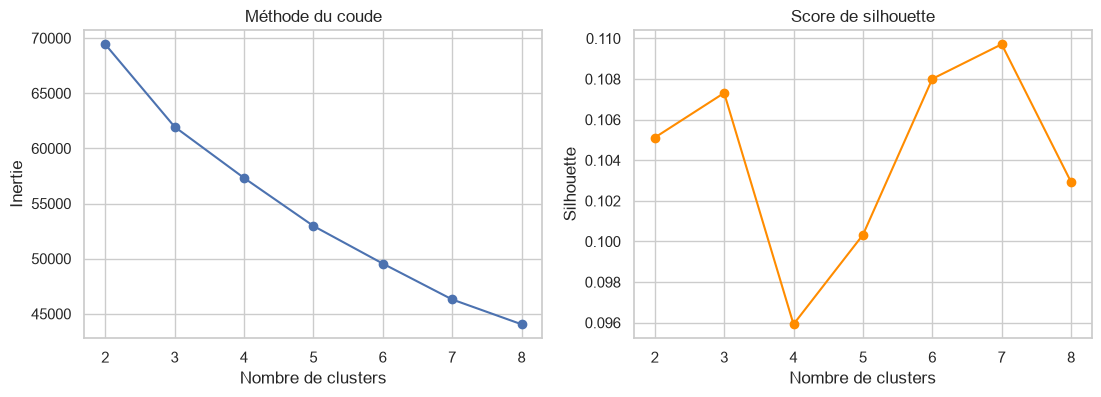

In [32]:
resultats_k = []
modeles_k = {}

for k in range(2, 9):
    modele_k = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = modele_k.fit_predict(X_cluster_apprentissage)

    resultats_k.append({
        "k": k,
        "inertie": modele_k.inertia_,
        "silhouette": silhouette_score(X_cluster_apprentissage, labels)
    })
    modeles_k[k] = modele_k

resultats_k = pd.DataFrame(resultats_k)
display(resultats_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(resultats_k["k"], resultats_k["inertie"], marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(resultats_k["k"], resultats_k["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Silhouette")
plt.show()

## 9. Sélection du nombre de clusters

Par défaut, le notebook retient le nombre de clusters ayant le meilleur score de silhouette. Après inspection des profils, cette valeur peut être remplacée manuellement si une autre segmentation est plus interprétable.

In [33]:
K_OPTIMAL = int(resultats_k.loc[resultats_k["silhouette"].idxmax(), "k"])

print("Nombre de clusters proposé :", K_OPTIMAL)

modele_cluster = modeles_k[K_OPTIMAL]
labels_apprentissage = modele_cluster.predict(X_cluster_apprentissage)
labels_validation = modele_cluster.predict(X_cluster_validation)
labels_test = modele_cluster.predict(X_cluster_test)

Nombre de clusters proposé : 7


## 10. Distances aux centres de clusters

Le numéro du cluster est une variable catégorielle. La distance au centre du cluster mesure quant à elle le degré de ressemblance avec le profil type du groupe. Une grande distance peut signaler un profil frontière ou atypique.

In [34]:
def informations_cluster(modele, matrice):
    distances_tous_centres = modele.transform(matrice)
    cluster = distances_tous_centres.argmin(axis=1)
    distance_centre = distances_tous_centres.min(axis=1)
    deux_distances = np.sort(distances_tous_centres, axis=1)[:, :2]
    marge_cluster = deux_distances[:, 1] - deux_distances[:, 0]
    return cluster, distance_centre, marge_cluster

cluster_train_ancien, distance_train_ancien, marge_train_ancien = informations_cluster(
    modele_cluster, X_cluster_apprentissage
)
cluster_validation, distance_validation, marge_validation = informations_cluster(
    modele_cluster, X_cluster_validation
)
cluster_test, distance_test, marge_test = informations_cluster(
    modele_cluster, X_cluster_test
)

train_prepare.loc[masque_apprentissage, "cluster_rh"] = cluster_train_ancien
train_prepare.loc[masque_validation, "cluster_rh"] = cluster_validation
train_prepare.loc[masque_apprentissage, "distance_cluster"] = distance_train_ancien
train_prepare.loc[masque_validation, "distance_cluster"] = distance_validation
train_prepare.loc[masque_apprentissage, "marge_cluster"] = marge_train_ancien
train_prepare.loc[masque_validation, "marge_cluster"] = marge_validation

test_prepare["cluster_rh"] = cluster_test
test_prepare["distance_cluster"] = distance_test
test_prepare["marge_cluster"] = marge_test

train_prepare["cluster_rh"] = train_prepare["cluster_rh"].astype("Int64").astype(str)
test_prepare["cluster_rh"] = test_prepare["cluster_rh"].astype(str)

## 11. Description métier des clusters

Les moyennes et médianes permettent de caractériser chaque groupe. Le taux de départ est calculé seulement après la création des clusters afin d’interpréter leur niveau de risque.

In [35]:
profil_clusters = train_prepare.groupby("cluster_rh").agg(
    effectif=("id", "count"),
    taux_depart=("target", "mean"),
    age_moyen=("age", "mean"),
    anciennete_moyenne=("anciennete", "mean"),
    engagement_moyen=("engagement_moyen", "mean"),
    performance_moyenne=("performance_moyenne", "mean"),
    ratio_salaire_median=("ratio_salaire_reference", "median"),
    jours_absence_moyens=("jours_abs_6m", "mean"),
    absences_non_justifiees=("abs_non_just_6m", "mean"),
    distance_moyenne=("distance_cluster", "mean")
)

profil_clusters["taux_depart"] = profil_clusters["taux_depart"].mul(100)

display(profil_clusters.round(3).sort_values("taux_depart", ascending=False))

,effectif,taux_depart,age_moyen,anciennete_moyenne,engagement_moyen,performance_moyenne,ratio_salaire_median,jours_absence_moyens,absences_non_justifiees,distance_moyenne
cluster_rh,,,,,,,,,,
4,13,15.385,33.668,2.730,3.659,3.393,10.221,1.231,0.000,5.654
2,470,14.468,36.185,1.833,3.078,3.399,0.976,6.970,1.570,4.295
3,2068,12.282,35.515,1.859,3.105,3.079,0.979,0.971,0.030,3.085
0,303,12.211,39.665,6.062,3.852,3.724,1.017,1.218,0.043,3.596
6,1259,10.167,36.028,2.203,3.505,4.038,0.995,1.029,0.033,3.145
5,11,9.091,34.155,1.569,3.338,3.177,1.007,42.364,0.636,4.445
1,1320,4.697,36.942,2.810,4.261,3.297,1.028,1.022,0.031,3.193


## 12. Catégories dominantes dans chaque cluster

Cette synthèse complète les moyennes numériques en affichant le poste, le département, le contrat et le grade les plus fréquents dans chaque groupe.

In [36]:
def modalite_dominante(serie):
    modes = serie.mode()
    return modes.iloc[0] if len(modes) else np.nan

categories_clusters = train_prepare.groupby("cluster_rh").agg(
    poste_dominant=("poste", modalite_dominante),
    departement_dominant=("departement", modalite_dominante),
    contrat_dominant=("contrat", modalite_dominante),
    grade_dominant=("grade", modalite_dominante),
    site_dominant=("code_site", modalite_dominante)
)

display(categories_clusters)

,poste_dominant,departement_dominant,contrat_dominant,grade_dominant,site_dominant
cluster_rh,,,,,
0,CONSEILLER CLIENT,DEP04,CDI,G2,ABJ-PLT
1,CONSEILLER COMMERCIAL,DEP04,CDI,G2,ABJ-PLT
2,CONSEILLER CLIENT,DEP04,CDI,G2,ABJ-PLT
3,CONSEILLER CLIENT,DEP04,CDI,G2,ABJ-PLT
4,TECHNICIEN RÉSEAU,DEP02,CDI,G1,ABJ-PLT
5,CONSEILLER COMMERCIAL,DEP03,CDI,G2,ABJ-COC
6,CONSEILLER CLIENT,DEP04,CDI,G2,ABJ-PLT


## 13. Taux de départ par cluster

Un cluster utile pour la compréhension RH doit présenter un profil cohérent et éventuellement un taux de départ différent du taux global.

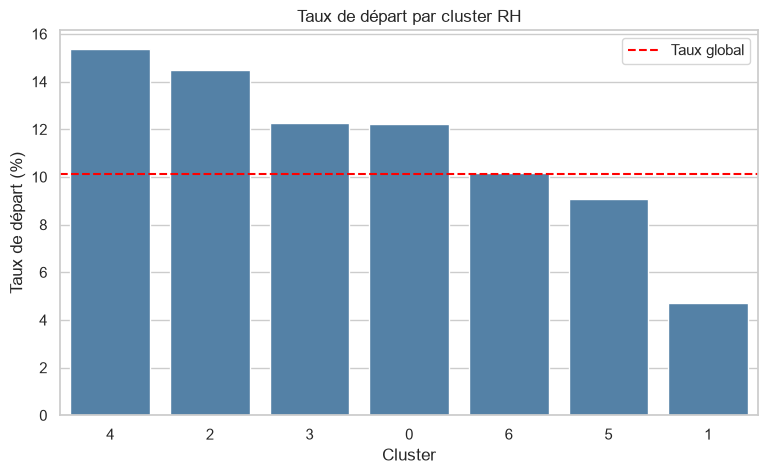

In [37]:
plt.figure(figsize=(9, 5))
ordre_clusters = profil_clusters.sort_values("taux_depart", ascending=False).index

sns.barplot(
    data=profil_clusters.reset_index(),
    x="cluster_rh",
    y="taux_depart",
    order=ordre_clusters,
    color="steelblue"
)
plt.axhline(train["target"].mean() * 100, color="red", linestyle="--", label="Taux global")
plt.title("Taux de départ par cluster RH")
plt.xlabel("Cluster")
plt.ylabel("Taux de départ (%)")
plt.legend()
plt.show()

## 14. Visualisation PCA des profils

La PCA projette les données préparées dans un plan à deux dimensions. Cette représentation aide à observer la séparation globale des profils, mais elle ne conserve qu’une partie de l’information originale.

Variance expliquée par les deux axes : 30.39 %


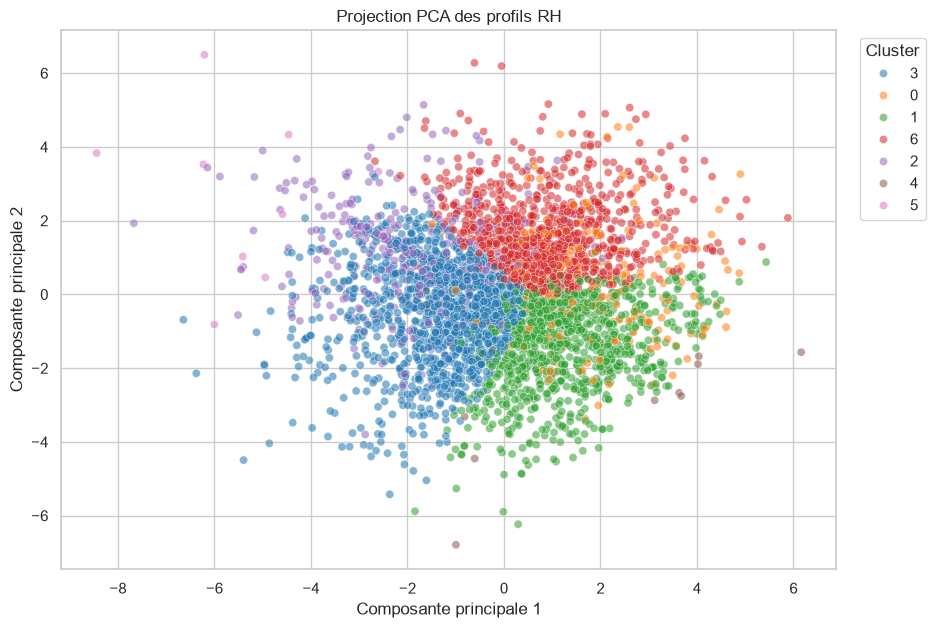

In [38]:
pca = PCA(n_components=2, random_state=42)
coordonnees_pca = pca.fit_transform(X_cluster_apprentissage)

visualisation_pca = pd.DataFrame({
    "axe_1": coordonnees_pca[:, 0],
    "axe_2": coordonnees_pca[:, 1],
    "cluster_rh": cluster_train_ancien.astype(str),
    "target": train_prepare.loc[masque_apprentissage, "target"].values
})

print("Variance expliquée par les deux axes :", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=visualisation_pca,
    x="axe_1",
    y="axe_2",
    hue="cluster_rh",
    alpha=0.55,
    s=35,
    palette="tab10"
)
plt.title("Projection PCA des profils RH")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 15. Détection d’anomalies avec Isolation Forest

Isolation Forest attribue un score d’anomalie à chaque observation. Le modèle est ajusté uniquement sur la partie historique d’apprentissage. Un score élevé indique un profil plus atypique par rapport aux autres observations.

In [39]:
modele_anomalie = IsolationForest(
    n_estimators=500,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)
modele_anomalie.fit(X_cluster_apprentissage)

def ajouter_scores_anomalie(matrice):
    score_normalite = modele_anomalie.score_samples(matrice)
    score_anomalie = -score_normalite
    anomalie = (modele_anomalie.predict(matrice) == -1).astype(int)
    return score_anomalie, anomalie

score_train_ancien, anomalie_train_ancien = ajouter_scores_anomalie(X_cluster_apprentissage)
score_validation, anomalie_validation = ajouter_scores_anomalie(X_cluster_validation)
score_test, anomalie_test = ajouter_scores_anomalie(X_cluster_test)

train_prepare.loc[masque_apprentissage, "score_anomalie"] = score_train_ancien
train_prepare.loc[masque_validation, "score_anomalie"] = score_validation
train_prepare.loc[masque_apprentissage, "profil_atypique"] = anomalie_train_ancien
train_prepare.loc[masque_validation, "profil_atypique"] = anomalie_validation

test_prepare["score_anomalie"] = score_test
test_prepare["profil_atypique"] = anomalie_test

print("Profils atypiques train :", int(train_prepare["profil_atypique"].sum()))
print("Profils atypiques test :", int(test_prepare["profil_atypique"].sum()))

Profils atypiques train : 162
Profils atypiques test : 58


## 16. Analyse des profils atypiques

Cette cellule compare le taux de départ des profils considérés comme atypiques à celui des profils ordinaires. Un écart n’est pas garanti : l’anomalie décrit la rareté, pas nécessairement le risque de départ.

In [40]:
analyse_anomalies = train_prepare.groupby("profil_atypique")["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)
analyse_anomalies["taux_depart"] = analyse_anomalies["taux_depart"].mul(100)

display(analyse_anomalies.round(3))

colonnes_affichage = [
    "id", "date_reference", "poste", "departement", "grade",
    "engagement_actuel", "ratio_salaire_reference", "jours_abs_6m",
    "score_anomalie", "target"
]

display(
    train_prepare.sort_values("score_anomalie", ascending=False)[colonnes_affichage].head(20)
)

,effectif,departs,taux_depart
profil_atypique,,,
0.0,5282,524,9.920
1.0,162,28,17.284


,id,date_reference,poste,departement,grade,engagement_actuel,ratio_salaire_reference,jours_abs_6m,score_anomalie,target
765,OBS000766,2022-06-30,TECHNICIEN RÉSEAU,DEP03,G1,2.54,0.900538,47,0.577107,1
4238,OBS004239,2024-06-30,MANAGER RH,DEP06,G4,2.89,0.830055,11,0.562943,0
463,OBS000464,2022-06-30,ANALYSTE QOS,DEP03,G4,1.77,1.051357,4,0.559671,1
1364,OBS001365,2022-12-31,CHARGÉ MARKETING,DEP07,G3,2.66,1.010479,46,0.557564,0
2340,OBS002341,2023-06-30,DÉVELOPPEUR,DEP08,G1,2.01,0.758621,11,0.554956,1
3777,OBS003778,2023-12-31,MANAGER ACHATS,DEP10,G5,3.67,1.004082,9,0.551496,0
3418,OBS003419,2023-12-31,CONTRÔLEUR DE GESTION,DEP05,G3,2.76,0.920114,6,0.549921,0
1295,OBS001296,2022-12-31,MANAGER SERVICE CLIENT,DEP04,G5,1.96,0.747852,5,0.546654,1
379,OBS000380,2022-06-30,MANAGER SERVICE CLIENT,DEP04,G5,2.77,0.735952,8,0.545580,0
3822,OBS003823,2023-12-31,LOGISTICIEN,DEP10,G3,2.73,0.860969,6,0.544468,1


## 17. Préparation de la comparaison supervisée

Deux ensembles de variables sont créés :

- **baseline** : variables préparées sans clustering ni anomalie ;
- **enrichi** : mêmes variables plus `cluster_rh`, `distance_cluster`, `marge_cluster`, `score_anomalie` et `profil_atypique`.

La validation reste juin 2024.

In [41]:
colonnes_brutes_a_retirer = [
    "target", "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]

variables_non_supervisees = [
    "cluster_rh", "distance_cluster", "marge_cluster",
    "score_anomalie", "profil_atypique"
]

X_enrichi = train_prepare.drop(columns=colonnes_brutes_a_retirer)
X_baseline = X_enrichi.drop(columns=variables_non_supervisees)
y = train_prepare["target"]

X_train_base = X_baseline.loc[masque_apprentissage].copy()
X_val_base = X_baseline.loc[masque_validation].copy()
X_train_enrichi = X_enrichi.loc[masque_apprentissage].copy()
X_val_enrichi = X_enrichi.loc[masque_validation].copy()
y_train = y.loc[masque_apprentissage]
y_val = y.loc[masque_validation]

print("Variables baseline :", X_train_base.shape[1])
print("Variables enrichies :", X_train_enrichi.shape[1])

Variables baseline : 54
Variables enrichies : 59


## 18. Fonction d’entraînement et d’optimisation du seuil

La même configuration CatBoost est utilisée pour les deux ensembles. Cela permet d’attribuer plus justement une éventuelle différence aux variables non supervisées.

In [42]:
def entrainer_et_evaluer(X_train_modele, X_val_modele, nom_modele):
    colonnes_categorielles = X_train_modele.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=7,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )

    modele.fit(
        X_train_modele,
        y_train,
        cat_features=colonnes_categorielles,
        eval_set=(X_val_modele, y_val),
        early_stopping_rounds=150
    )

    probabilites = modele.predict_proba(X_val_modele)[:, 1]
    lignes = []

    for seuil in np.arange(0.20, 0.81, 0.01):
        predictions = (probabilites >= seuil).astype(int)
        lignes.append({
            "seuil": round(float(seuil), 2),
            "f1": f1_score(y_val, predictions),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "rappel": recall_score(y_val, predictions, zero_division=0)
        })

    scores = pd.DataFrame(lignes)
    meilleure = scores.loc[scores["f1"].idxmax()]

    resume = {
        "modele": nom_modele,
        "iteration": modele.get_best_iteration(),
        "auc": roc_auc_score(y_val, probabilites),
        "seuil": meilleure["seuil"],
        "f1": meilleure["f1"],
        "precision": meilleure["precision"],
        "rappel": meilleure["rappel"]
    }

    return modele, probabilites, scores, resume

## 19. Comparaison baseline contre modèle enrichi

Le résultat déterminera si les clusters et scores d’anomalie améliorent réellement la prédiction sur la période future.

In [43]:
modele_baseline, proba_baseline, seuils_baseline, resume_baseline = entrainer_et_evaluer(
    X_train_base, X_val_base, "CatBoost sans clustering"
)

modele_enrichi, proba_enrichi, seuils_enrichi, resume_enrichi = entrainer_et_evaluer(
    X_train_enrichi, X_val_enrichi, "CatBoost avec clustering"
)

comparaison_modeles = pd.DataFrame([resume_baseline, resume_enrichi])
display(comparaison_modeles)

GAIN_F1 = resume_enrichi["f1"] - resume_baseline["f1"]
print("Gain F1 apporté par les variables non supervisées :", round(GAIN_F1, 4))

,modele,iteration,auc,seuil,f1,precision,rappel
0,CatBoost sans clustering,312,0.721388,0.53,0.310502,0.220065,0.527132
1,CatBoost avec clustering,182,0.723128,0.62,0.326797,0.282486,0.387597


Gain F1 apporté par les variables non supervisées : 0.0163


## 20. Interprétation de la comparaison

Un gain positif et stable justifie l’intégration des nouvelles variables. Un gain nul ou négatif reste un résultat utile : la segmentation peut conserver une forte valeur descriptive RH sans améliorer le classement supervisé.

In [44]:
meilleur_resume = max([resume_baseline, resume_enrichi], key=lambda x: x["f1"])

print("Meilleur modèle :", meilleur_resume["modele"])
print("F1 :", round(meilleur_resume["f1"], 4))
print("AUC :", round(meilleur_resume["auc"], 4))
print("Seuil :", round(meilleur_resume["seuil"], 2))
print("Précision :", round(meilleur_resume["precision"], 4))
print("Rappel :", round(meilleur_resume["rappel"], 4))

Meilleur modèle : CatBoost avec clustering
F1 : 0.3268
AUC : 0.7231
Seuil : 0.62
Précision : 0.2825
Rappel : 0.3876


## 21. Importance des variables non supervisées

Si le modèle enrichi est retenu, cette cellule indique le poids accordé aux nouvelles variables parmi l’ensemble des prédicteurs.

In [45]:
importance_enrichie = pd.DataFrame({
    "variable": X_train_enrichi.columns,
    "importance": modele_enrichi.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance_enrichie.head(30))

display(
    importance_enrichie.loc[
        importance_enrichie["variable"].isin(variables_non_supervisees)
    ]
)

,variable,importance
39,ratio_salaire_reference,15.878457
42,engagement_moyen,10.053033
12,engagement_actuel,6.378390
55,distance_cluster,4.756510
57,score_anomalie,4.048085
35,age,3.497449
36,anciennete,3.150259
6,grade,2.794362
33,code_site,2.793160
54,cluster_rh,2.585627


,variable,importance
55,distance_cluster,4.756510
57,score_anomalie,4.048085
54,cluster_rh,2.585627
56,marge_cluster,1.402644
58,profil_atypique,0.218824


## 22. Export des profils et des résultats

Les profils de clusters, les résultats de la comparaison et les affectations du test sont exportés dans `reports`. Ces fichiers pourront alimenter le rapport et le dashboard.

In [46]:
profil_clusters.round(4).to_csv(
    "../reports/profils_clusters_rh.csv"
)

comparaison_modeles.to_csv(
    "../reports/comparaison_clustering_catboost.csv",
    index=False
)

affectations_test = pd.DataFrame({
    "id": test_prepare["id"],
    "cluster_rh": test_prepare["cluster_rh"],
    "distance_cluster": test_prepare["distance_cluster"],
    "marge_cluster": test_prepare["marge_cluster"],
    "score_anomalie": test_prepare["score_anomalie"],
    "profil_atypique": test_prepare["profil_atypique"].astype(int)
})

affectations_test.to_csv(
    "../reports/affectations_clusters_test.csv",
    index=False
)

print("Exports terminés dans le dossier reports.")

Exports terminés dans le dossier reports.


## Conclusion

Ce notebook répond à deux questions différentes :

1. **Quels profils RH cachés existent dans l’entreprise ?**
2. **Ces profils améliorent-ils la prédiction des départs ?**

Le clustering garde une valeur métier même s’il n’améliore pas le F1. Il peut servir à nommer des segments, comparer leurs risques, construire des actions RH ciblées et enrichir le dashboard.

La décision d’intégrer les variables non supervisées au modèle final doit cependant dépendre du gain obtenu sur la validation temporelle, puis être confirmée sur plusieurs fenêtres temporelles.